In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from typing import Annotated
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_experimental.utilities import PythonREPL
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langchain.chat_models import init_chat_model


llm = init_chat_model("openai:gpt-4.1")

# 1) 검색 도구 (Tavily API 필요)
tavily_tool = TavilySearch(max_results=5)

# 2) 로컬 파이썬 실행 도구 (차트 생성 전용)
repl = PythonREPL()


@tool
def python_repl_tool(
  code: Annotated[str, "차트를 생성하기 위한 파이썬 코드"]  
):
    """파이썬 코드를 실행합니다. 출력은 print(...)로 표시해야 합니다."""
    try:
        result = repl.run(code)
    except BaseException as e:
        return f"실행 실패: {repr(e)}"
    return f"성공적으로 실행했습니다:\n'''python\n{code}\n'''\nStdout: {result}\n\nFINAL ANSWER"

C:\Users\HKIT\AppData\Local\Temp\ipykernel_3316\238539260.py:4: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.utilities import PythonREPL


In [3]:
# 3) 시스템 프롬프트 템플릿
def make_system_prompt(suffix: str):
    return (
        "당신은 다른 어시스턴트와 협업하는 유능한 AI입니다."
        "주어진 도구만 사용해 작업을 완수하세요."
        "최종 답변을 얻으면 반드시 'FINAL ANSWER'를 붙여 종료하세요."
        f"\n{suffix}"
    )

def get_next_node(last_message: BaseMessage, goto: str):
    if "FINAL ANSWER" in last_message.content:
        return END
    return goto

In [4]:
from typing import Literal
from langchain.agents import create_agent
from langgraph.graph import MessagesState
from langgraph.types import Command

# 4) 리서처 노드 (검색 전용)
research_agent = create_agent(
    model = llm,
    tools = [tavily_tool],
    system_prompt = make_system_prompt("당신은 리서치만 할 수 있습니다. 동료 차트 생성자와 협업하세요.")
)

def research_node(state: MessagesState) -> Command[Literal["chart_generator",END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "chart_generator")
    # 일부 모델/프로바이더 제약 회피: 마지막 메시지를 Human 역할로 래핑
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content, name="researcher")
    return Command(update={"messages": result["messages"]}, goto=goto)


In [5]:
# 5) 차트 생성 노드 (파이썬 실행 전용)
chart_agent = create_agent(
    model = llm,
    tools = [python_repl_tool],
    system_prompt = make_system_prompt("당신은 차트 생성만 할 수 있습니다. 동료 리서처와 협업하세요.")
)

def chart_node(state: MessagesState) -> Command[Literal["researcher", END]]:
    result = chart_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "researcher")
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content, name="chart_generator")
    return Command(update={"messages": result["messages"]}, goto=goto) 

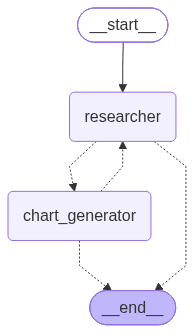

In [6]:
from IPython.display import Image, display

# 6) 그래프 구성
workflow = StateGraph(MessagesState)
workflow.add_node("researcher", research_node)
workflow.add_node("chart_generator", chart_node)
workflow.add_edge(START, "researcher")  # 리서처부터 시작
graph = workflow.compile()

# 다이어그램 표시
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

{'researcher': {'messages': [HumanMessage(content='지난 1년간 달러 환율 데이터를 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요.오늘은 2026-10-27입니다. 2026-10-27부터 거슬러 지난 12개월간의 USD/KRW 월별 환율을 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요.차트를 생성했으면 작업을 종료하세요.', additional_kwargs={}, response_metadata={}, id='6da4b1f4-7565-4f98-8df9-0754cb700a3a'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 1346, 'total_tokens': 1385, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_b50162a62f', 'id': 'chatcmpl-EdXXo35NKAbWgtSINn4R54CXDfKSt', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_ru

Python REPL can execute arbitrary code. Use with caution.
<string>:18: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) DejaVu Sans.
<string>:18: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
<string>:18: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
<string>:18: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
<string>:18: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
c:\agent-prg\ch04\ch04_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\agent-prg\ch04\ch04_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\agent-prg\ch04\ch04_env\Lib\site-pa

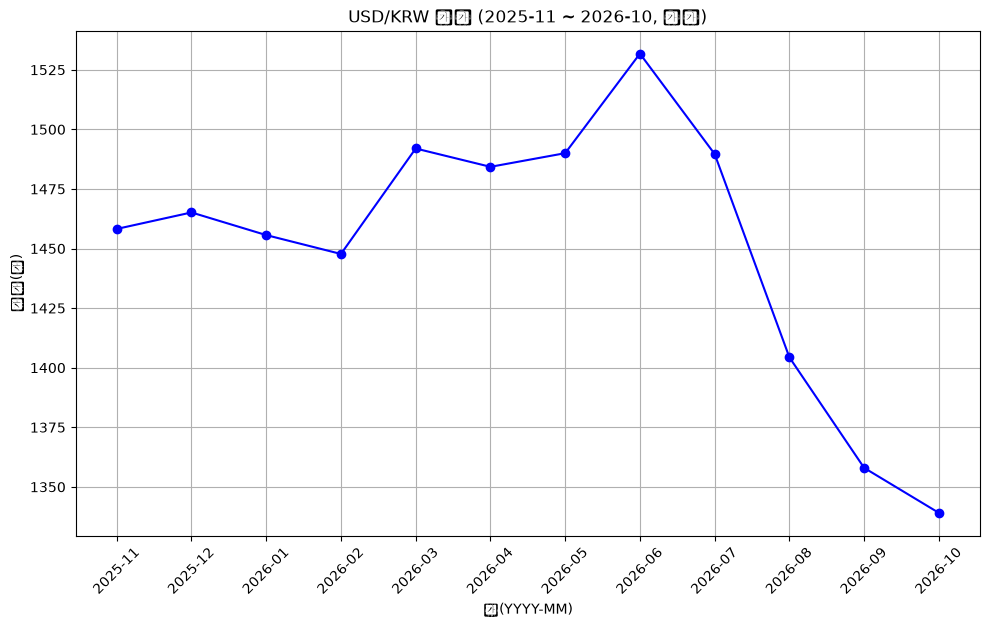

{'chart_generator': {'messages': [HumanMessage(content='지난 1년간 달러 환율 데이터를 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요.오늘은 2026-10-27입니다. 2026-10-27부터 거슬러 지난 12개월간의 USD/KRW 월별 환율을 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요.차트를 생성했으면 작업을 종료하세요.', additional_kwargs={}, response_metadata={}, id='6da4b1f4-7565-4f98-8df9-0754cb700a3a'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 1346, 'total_tokens': 1385, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_b50162a62f', 'id': 'chatcmpl-EdXXo35NKAbWgtSINn4R54CXDfKSt', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='

In [7]:
from datetime import date
today = date.today()

# 7) 실행
events = graph.stream(
    {
        "messages": [(
            "user",
            "지난 1년간 달러 환율 데이터를 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요."
            f"오늘은 {today}입니다. {today}부터 거슬러 지난 12개월간의 USD/KRW 월별 환율을 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요."
            "차트를 생성했으면 작업을 종료하세요."
        )]
    },
    {"recursion_limit": 150} # 안전장치: 최대 스텝 제한
)

for step in events:
    print(step) # 각 단계의 중간 결과/메시지 스트림 확인
    print("----")

In [8]:
from __future__ import annotations
from typing import Annotated, List, Dict, Optional, Literal
from typing_extensions import TypedDict


from pathlib import Path

from pydantic import BaseModel, Field

# LangGraph
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.types import Command

# LangChain
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage, BaseMessage, SystemMessage
from langchain_core.tools import tool

# Tools
from langchain_tavily import TavilySearch
from langchain_community.document_loaders import WebBaseLoader
from langchain_experimental.utilities import PythonREPL


# 1) 공용 상태 정의
class State(TypedDict):
    messages: Annotated[List[BaseMessage], add_messages]
    next: str
    
# 2) 리서치팀 도구
# Tavily 웹 검색: 상위 n개 결과를 반환
tavily_tool = TavilySearch(max_results=5)

@tool
def scrape_webpages(urls: List[str]):
    """요청한 웹 페이지 목록을 크롤링하여 본문 텍스트를 추출합니다."""
    loader = WebBaseLoader(
        urls,
        header_template={
            "User-Agent": (
                "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                "AppleWebKit/537.36 (KHTML, like Gecko) "
                "Chrome/122.0.0.0 Safari/537.36"
            )})
    docs = loader.load()
    return "\n\n".join(
        [
            f'<문서 제목="{doc.metadata.get("title", "")}">\n{doc.page_content}\n</문서>'
            for doc in docs
        ]
    )

C:\Users\HKIT\AppData\Local\Temp\ipykernel_3316\1395107422.py:22: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [9]:
# 3) 문서팀 도구
WORKING_DIRECTORY = Path.cwd() 

@tool
def create_outline(
    points: Annotated[List[str], "섹션/소제목 리스트"],     # @tool 함수의 인자, 인자 설명(문자열), 그래프 State 클래스에서는 리듀서
    file_name: Annotated[str, "개요를 저장할 파일 경로(상대/절대)"]):
    """개요(아웃라인)를 파일로 저장합니다."""
    path = (WORKING_DIRECTORY / file_name)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for i, p in enumerate(points):
            f.write(f"{i + 1}. {p}\n")
    return f"개요 저장 완료: {path}"

@tool
def read_document(
    file_name: Annotated[str, "읽을 파일 경로"],
    start: Annotated[Optional[int], "시작 줄(기본 0)"] = None,
    end: Annotated[Optional[int], "끝 줄(기본 None)"] = None):
    """지정한 텍스트 문서를 읽어 반환합니다(부분 범위 가능)."""
    path = (WORKING_DIRECTORY / file_name)
    with path.open("r", encoding="utf-8") as f:
        lines = f.readlines()
    start = 0 if start is None else start
    return "".join(lines[start:end])

@tool
def write_document(
    content: Annotated[str, "파일에 저장할 텍스트 콘텐츠"],
    file_name: Annotated[str, "저장할 파일 경로"]):
    """텍스트 문서를 새로 작성/덮어씁니다."""
    path = (WORKING_DIRECTORY / file_name)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        f.write(content)
    return f"문서 저장 완료: {path}"

@tool
def edit_document(
    file_name: Annotated[str, "수정할 파일 경로"],
    inserts: Annotated[
        Dict[int, str],
        "삽입할 위치(1부터 시작)와 텍스트의 딕셔너리",
    ]):
    """지정한 줄 번호 위치에 문장을 삽입합니다."""
    path = (WORKING_DIRECTORY / file_name)
    with path.open("r", encoding="utf-8") as f:
        lines = f.readlines()

    for line_no, text in sorted(inserts.items()):
        if 1 <= line_no <= len(lines) + 1:
            lines.insert(line_no - 1, text + "\n")
        else:
            return f"오류: 줄 번호 {line_no} 범위를 벗어났습니다."

    with path.open("w", encoding="utf-8") as f:
        f.writelines(lines)
    return f"문서 수정/저장 완료: {path}"

# 로컬 파이썬 실행(차트 등)
repl = PythonREPL()

@tool
def python_repl_tool(
    code: Annotated[str, "차트 생성 등 실행할 파이썬 코드(출력은 print로 표시)"],
):
    """파이썬 코드를 실행합니다. 결과를 보려면 print(...)를 사용하세요."""
    try:
        result = repl.run(code)
    except BaseException as e:
        return f"실행 실패: {repr(e)}"
    return f"성공적으로 실행했습니다:\n```python\n{code}\n```\nStdout: {result}"

In [10]:
# 4) "감독자(supervisor)" 노드 팩토리
#    - 멤버 이름 목록을 받아, 다음에 호출할 워커를 LLM이 결정
#    - Pydantic 스키마로 구조화된 출력 사용
def make_supervisor_node(llm, members: List[str]):
    options = ["FINISH", *members]

    system_prompt = (
        "당신은 다음 워커들을 관리하는 감독자입니다: "
        f"{members}. "
        "사용자 요청과 현재까지의 대화 메시지를 보고 "
        "다음에 실행할 워커를 한 명만 선택하세요. "
        "모든 작업이 끝났다면 FINISH를 선택하세요."
    )

    class Router(BaseModel):
        next: Literal[*options] = Field(..., description="다음 노드명 또는 FINISH")

    def supervisor_node(state: State):
        messages = [SystemMessage(content=system_prompt)] + state["messages"]
        decision = llm.with_structured_output(Router).invoke(messages)
        # 라우팅은 그래프(add_conditional_edges)가 수행 → 여기서는 next만 저장
        return {"next": decision.next}

    return supervisor_node

In [11]:
# 5) 리서치팀 (검색 + 스크래핑) 서브그래프
search_agent = create_agent(llm, tools=[tavily_tool])

def search_node(state: State) -> Command[Literal["supervisor"]]:
    """검색 워커: 질의 → 검색 결과 요약"""
    result = search_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="search")]},
        goto="supervisor",
    )

web_scraper_agent = create_agent(llm, tools=[scrape_webpages])

def web_scraper_node(state: State) -> Command[Literal["supervisor"]]:
    """스크래핑 워커: URL들 → 본문 추출"""
    result = web_scraper_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="web_scraper")]},
        goto="supervisor",
    )

research_supervisor_node = make_supervisor_node(llm, ["search", "web_scraper"])

# 리서치팀 그래프
def route_from_supervisor(state) -> str:
    # supervisor가 update로 저장한 값 이용
    nxt = state.get("next", "")
    if nxt == "FINISH":
        return END
    return nxt  # "search" 또는 "web_scraper"

research_builder = StateGraph(State)
research_builder.add_node("supervisor", research_supervisor_node)
research_builder.add_node("search", search_node)
research_builder.add_node("web_scraper", web_scraper_node)

research_builder.add_edge(START, "supervisor")
research_builder.add_conditional_edges(
    "supervisor",
    route_from_supervisor,
    {
        "search": "search",
        "web_scraper": "web_scraper",
        END: END,
    },
)

research_graph = research_builder.compile()

In [12]:
# 6) 문서팀 (개요/작성/차트) 서브그래프
note_taking_agent = create_agent(
    llm,
    tools=[create_outline, read_document],
    system_prompt="당신은 문서 개요를 만드는 어시스턴트입니다. 추가 질문 없이 개요를 작성하세요."
)

def note_taking_node(state: State) -> Command[Literal["supervisor"]]:
    """노트테이커: 개요 작성/읽기"""
    result = note_taking_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="note_taker")]},
        goto="supervisor",
    )

doc_writer_agent = create_agent(
    llm,
    tools=[write_document, edit_document, read_document],
    system_prompt="당신은 개요를 바탕으로 초안을 작성/수정하는 문서 작성기입니다. 추가 질문 없이 바로 수행하세요."
)

def doc_writing_node(state: State) -> Command[Literal["supervisor"]]:
    """문서 작성자: 초안 작성/수정"""
    result = doc_writer_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="doc_writer")]},
        goto="supervisor",
    )

chart_generating_agent = create_agent(
    llm,
    tools=[read_document, python_repl_tool],
    system_prompt="당신은 파이썬 코드를 실행해 차트를 생성/저장하는 작업을 담당합니다."
)

def chart_generating_node(state: State) -> Command[Literal["supervisor"]]:
    """차트 생성자: 파이썬 실행(차트)"""
    result = chart_generating_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="chart_generator")]},
        goto="supervisor",
    )

doc_writing_supervisor_node = make_supervisor_node(
    llm, ["note_taker", "doc_writer", "chart_generator"]
)

# 문서팀 그래프
paper_writing_builder = StateGraph(State)
paper_writing_builder.add_node("supervisor", doc_writing_supervisor_node)
paper_writing_builder.add_node("note_taker", note_taking_node)
paper_writing_builder.add_node("doc_writer", doc_writing_node)
paper_writing_builder.add_node("chart_generator", chart_generating_node)

paper_writing_builder.add_edge(START, "supervisor")
paper_writing_builder.add_conditional_edges(
    "supervisor",
    route_from_supervisor,
    {
        "note_taker": "note_taker",
        "doc_writer": "doc_writer",
        "chart_generator": "chart_generator",
        END: END,
    },
)
paper_writing_graph = paper_writing_builder.compile()

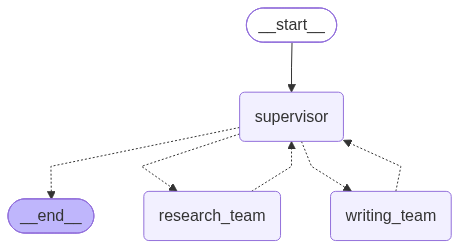

In [13]:
# 7) 최상위 그래프 (팀 간 오케스트레이션)
top_supervisor_node = make_supervisor_node(llm, ["research_team", "writing_team"])

def call_research_team(state: State) -> Command[Literal["supervisor"]]:
    """리서치팀 서브그래프 호출"""
    # 마지막 메시지만 넘겨도 되지만, 필요하다면 전체 state["messages"]를 넘기는 설계로 바꿀 수 있음
    response = research_graph.invoke({"messages": state["messages"][-1]})
    return Command(
        update={"messages": [HumanMessage(content=response["messages"][-1].content, name="research_team")]},
        goto="supervisor",
    )

def call_paper_writing_team(state: State) -> Command[Literal["supervisor"]]:
    """문서팀 서브그래프 호출"""
    response = paper_writing_graph.invoke({"messages": state["messages"][-1]})
    return Command(
        update={"messages": [HumanMessage(content=response["messages"][-1].content, name="writing_team")]},
        goto="supervisor",
    )

# 최상위 그래프
super_builder = StateGraph(State)
super_builder.add_node("supervisor", top_supervisor_node)
super_builder.add_node("research_team", call_research_team)
super_builder.add_node("writing_team", call_paper_writing_team)

super_builder.add_edge(START, "supervisor")
super_builder.add_conditional_edges(
    "supervisor",
    route_from_supervisor,
    {
        "research_team": "research_team",
        "writing_team": "writing_team",
        END: END,
    },
)
super_graph = super_builder.compile()

# 다이어그램 표시
try:
    display(Image(super_graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [15]:
# 8) 사용 예시 (스트림 실행)
print("=== 실행 예시: '환율' 간단 리포트 생성 ===")
events = super_graph.stream(
    {"messages": [("user", "1)최근 1년의 달러 환율을 인터넷에서 조사하고 2) python_repl_tool로 달러 환율을 라인차트를 그린 후 저장해주고 3) 짧은 보고서를 markdown 형태로 작성해 주세요.")]},
    {"recursion_limit": 150},
)
for step in events:
    print(step)
    print("---")

print("\n작업 디렉터리:", WORKING_DIRECTORY)

=== 실행 예시: '환율' 간단 리포트 생성 ===
{'supervisor': {'next': 'research_team'}}
---
{'research_team': {'messages': [HumanMessage(content="대표적 신뢰도 높은 월별 환율 수치를 확보할 수 있었으므로, 아래 내용으로 차트를 바로 제작하겠습니다.\n\n- (예시) 2023-06~2024-06 월별 USD/KRW 환율:  \n  1,292, 1,299, 1,320, 1,329, 1,355, 1,321, 1,299, 1,294, 1,301, 1,332, 1,376, 1,342, 1,364\n\n이제 Python 코드로 라인차트를 그리고 이미지를 저장하겠습니다.\n```python\nimport matplotlib.pyplot as plt\n\n# 월별 데이터\nmonths = [\n    '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12',\n    '2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06'\n]\nrates = [1292, 1299, 1320, 1329, 1355, 1321, 1299, 1294, 1301, 1332, 1376, 1342, 1364]\n\nplt.figure(figsize=(10,5))\nplt.plot(months, rates, marker='o', linestyle='-', color='blue')\nplt.title('월별 원-달러 환율 (2023-06 ~ 2024-06)')\nplt.xlabel('월')\nplt.ylabel('원/달러 환율')\nplt.xticks(rotation=45)\nplt.grid(True, linestyle='--', alpha=0.5)\nplt.tight_layout()\nplt.savefig('usdkrw_linechart.png')\nplt.close()\n```\